# Apparel Image Caption · 2. Training and results

Notebook 1 showed that the raw H&M captions cannot be used as alt-text. This notebook covers what
was done about it and how well the result works:

1. the caption rewrite that produced the training targets,
2. fine-tuning Florence-2-base on those targets,
3. a comparison with three zero-shot baselines on a held-out test split,
4. examples, including where the model goes wrong.

Everything here is read from files written by the pipeline scripts (`scripts/02` to `05`), which
ran as GPU jobs. Nothing is retrained in the notebook.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils import ALT_TEXT_TARGET_CHARS, DATA_DIR, OUTPUT_DIR
from utils.io import read_jsonl
from utils.plotting import (BLUE, AXIS, SERIES, apply_style, caption_comparison, histogram,
                              ranked_bars, reference_line)
from utils.textnorm import non_visible_terms

apply_style()
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 1)

results = pd.read_csv(OUTPUT_DIR / "results.csv", index_col="system")
predictions = pd.read_csv(OUTPUT_DIR / "test_predictions.csv", dtype={"id": str})
train_log = pd.read_csv(OUTPUT_DIR / "train_log.csv")
val_log = pd.read_csv(OUTPUT_DIR / "val_log.csv")
summary = json.loads((OUTPUT_DIR / "train_summary.json").read_text())
alt = pd.DataFrame(read_jsonl(DATA_DIR / "alt_text.jsonl"))

OURS = "florence_finetuned"
OURS_LABEL = "Florence-2-base, fine-tuned (ours)"
print(f"{len(predictions):,} test images")

970 test images


## 1. Training targets: the caption rewrite

Each raw caption was rewritten once by a text-only LLM (Qwen2.5-7B-Instruct) under fixed rules: one
sentence, sentence case, about 125 characters, visible facts only, nothing added. Every rewrite was
then checked automatically and sent back with the reason, up to twice, if it failed. Rewrites
that still failed were excluded from training and from evaluation.

The LLM never sees the image, so these targets are *silver* labels: cleaner than the originals,
but not verified against the photo. Test images whose rewrite was rejected have no reference
and are left out of the test scores below.

In [2]:
kept = alt[alt["ok"]]
lengths = kept["alt_text"].str.len()
print(f"Captions rewritten:            {len(alt):,}")
print(f"Passed every check:            {len(kept):,} ({len(kept) / len(alt):.1%})")
print(f"Needed at least one retry:     {(alt['attempts'] > 1).sum():,}")
print(f"Median length:                 {lengths.median():.0f} characters "
      f"(raw captions: {alt['raw_caption'].str.len().median():.0f})")
print(f"Within {ALT_TEXT_TARGET_CHARS} characters:         {(lengths <= ALT_TEXT_TARGET_CHARS).mean():.1%}")
print(f"Containing a non-visible term: {kept['alt_text'].map(lambda t: bool(non_visible_terms(t))).mean():.1%} "
      f"(raw captions: {alt['raw_caption'].map(lambda t: bool(non_visible_terms(t))).mean():.1%})")

display(kept.sample(6, random_state=11)[["raw_caption", "alt_text"]].reset_index(drop=True))

Captions rewritten:            20,491
Passed every check:            19,363 (94.5%)
Needed at least one retry:     10,034
Median length:                 97 characters (raw captions: 163)
Within 125 characters:         89.4%


Containing a non-visible term: 0.0% (raw captions: 87.8%)


,raw_caption,alt_text
0,solid light turquoise ankle-length suit trousers in woven fabric with a high waist concealed hook-and-eye fastener and zip fly side pockets fake back pockets and straight slightly wider legs,"Light turquoise ankle-length suit trousers with a high waist, zip fly and side pockets."
1,check black blouse in woven fabric with a smocked bodice square neckline and long puff sleeves with concealed elastication over the shoulders and wide smocking at the cuffs,"Black check blouse with a smocked bodice, square neckline, long puff sleeves and wide smocking at the cuffs."
2,dot light blue short dress in patterned viscose jersey with a v-neck with a sewn-in wrapover and frill trim at the top short sleeves a seam with a drawstring at the waist and a double layered skirt with a frill trim unlined,"Light blue dotted short dress with a V-neck, short sleeves, a drawstring waist and a frill trim."
3,solid light blue fitted top in ribbed cotton jersey with a v-neck long sleeves and overlocked edges at the cuffs and hem,Light blue ribbed fitted top with a V-neck and long sleeves.
4,all over pattern yellow short dress in a patterned crepe weave with a frill-trimmed v-neck elasticated seam at the waist and long sleeves with elasticated cuffs unlined,"Yellow patterned crepe dress with a frill-trimmed V-neck, elasticated waist and long elasticated sleeves."
5,solid black joggers in sweatshirt fabric made from a cotton blend with an elasticated drawstring waist welt side pockets and an open back pocket tapered legs with ribbed hems soft brushed inside,"Black joggers with an elasticated drawstring waist, side pockets and an open front pocket."


## 2. Fine-tuning

Florence-2-base (231M parameters) was fine-tuned end to end. The input is the image plus the
model's built-in `<CAPTION>` task prompt, and the target is the rewritten alt-text. After each
epoch the model was scored on the validation split, and the checkpoint with the best validation
CIDEr was kept. Epoch 0 is the pretrained model before any training.

Training examples: 17,418 | batch size 16 | learning rate 1e-05 | 32 minutes on one GPU
Best epoch: 4 (validation CIDEr 291.3; pretrained model: 16.9)


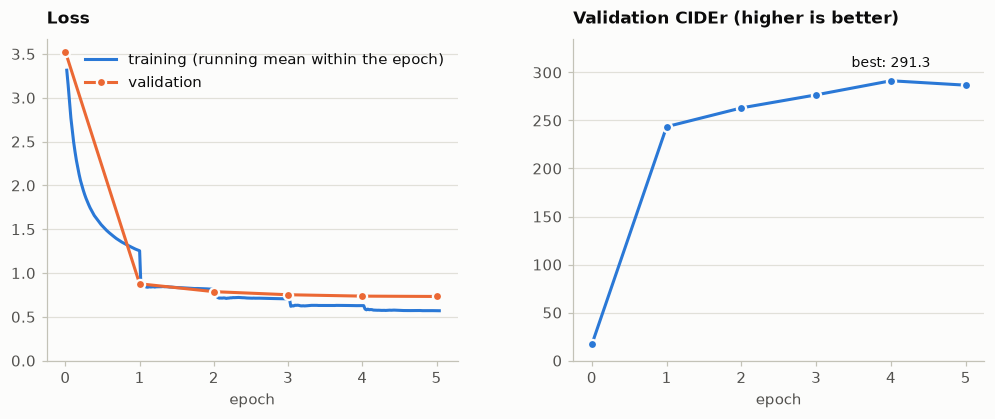

,train_loss,val_loss,val_cider,minutes
epoch,,,,
0,,3.526,16.9,0
1,1.251,0.877,243.5,7
2,0.816,0.787,263.1,13
3,0.705,0.752,276.7,19
4,0.627,0.736,291.3,25
5,0.570,0.732,286.7,32


In [3]:
print(f"Training examples: {summary['train_examples']:,} | batch size {summary['batch_size']} | "
      f"learning rate {summary['lr']} | {summary['minutes']:.0f} minutes on one GPU")
print(f"Best epoch: {summary['best_epoch']} (validation CIDEr {summary['best_val_cider']:.1f}; "
      f"pretrained model: {summary['pretrained_val_cider']:.1f})")

steps_per_epoch = train_log.groupby("epoch")["step"].max().iloc[0]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.28})

left.plot(train_log["step"] / steps_per_epoch, train_log["loss"], color=SERIES[0], linewidth=2,
          label="training (running mean within the epoch)")
left.plot(val_log["epoch"], val_log["val_loss"], color=SERIES[1], linewidth=2, marker="o",
          markersize=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5, label="validation")
left.set_title("Loss")
left.set_xlabel("epoch")
left.set_ylim(bottom=0)
left.grid(axis="y")
left.legend(loc="upper right")

right.plot(val_log["epoch"], val_log["val_cider"], color=SERIES[0], linewidth=2, marker="o",
           markersize=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
best = val_log.loc[val_log["val_cider"].idxmax()]
right.annotate(f"best: {best.val_cider:.1f}", xy=(best.epoch, best.val_cider), xytext=(0, 9),
               textcoords="offset points", ha="center", fontsize=9)
right.set_title("Validation CIDEr (higher is better)")
right.set_xlabel("epoch")
right.set_ylim(0, val_log["val_cider"].max() * 1.15)
right.set_xticks(val_log["epoch"])
right.grid(axis="y")
plt.show()

display(val_log.set_index("epoch").style.format(
    {"train_loss": "{:.3f}", "val_loss": "{:.3f}", "val_cider": "{:.1f}", "minutes": "{:.0f}"}, na_rep=""))

## 3. Test results

All systems caption the same held-out test images, none of which (and no other image sharing a
description with them) was seen in training.

- **Reference metrics** (BLEU-4, ROUGE-L, METEOR, CIDEr) measure word overlap with the reference
  alt-text. They reward matching the *style* of the references, so the zero-shot models, which
  were never shown that style, are at a disadvantage on these by construction. All are shown
  multiplied by 100; CIDEr's raw range is 0 to 10, so its maximum here is 1000.
- **CLIPScore** needs no reference: it measures how well the caption matches the image according
  to CLIP. It is the fairer comparison across writing styles.
- **Alt-text checks** are simple properties of the text: length, sentence form, and whether it
  mentions things that cannot be seen or a person.

The last two rows are not model outputs. They show the same measurements for the reference
alt-text and for the original H&M captions.

In [4]:
overlap = ["BLEU-4", "ROUGE-L", "METEOR", "CIDEr", "CLIPScore"]
print("Agreement with the reference (first four) and with the image (CLIPScore). Higher is better.")
display(results[overlap].style.format("{:.1f}", na_rep=""))
print("Alt-text checks.")
display(results.drop(columns=overlap).style.format("{:.1f}", na_rep=""))

Agreement with the reference (first four) and with the image (CLIPScore). Higher is better.


,BLEU-4,ROUGE-L,METEOR,CIDEr,CLIPScore
system,,,,,
"BLIP-base, zero-shot",2.3,22.1,18.0,18.5,77.9
"Florence-2-base, zero-shot (caption prompt)",1.8,22.6,17.4,16.5,77.9
"Florence-2-base, zero-shot (detailed-caption prompt)",0.0,10.2,8.3,5.3,65.4
"Florence-2-base, fine-tuned (ours)",37.3,63.9,64.0,281.6,80.5
Reference alt-text (LLM rewrite of the H&M caption),,,,,79.7
Raw H&M caption,,,,,79.3


Alt-text checks.


,mean chars,<= 125 chars %,sentence case + period %,non-visible term %,mentions a person %,mentions the image %
system,,,,,,
"BLIP-base, zero-shot",48.0,97.8,0.0,3.9,9.7,8.6
"Florence-2-base, zero-shot (caption prompt)",46.8,100.0,97.6,0.2,0.7,0.3
"Florence-2-base, zero-shot (detailed-caption prompt)",59.1,100.0,100.0,0.0,0.0,100.0
"Florence-2-base, fine-tuned (ours)",91.4,94.2,100.0,0.0,0.0,0.0
Reference alt-text (LLM rewrite of the H&M caption),94.6,90.0,100.0,0.0,0.0,0.0
Raw H&M caption,163.3,27.9,0.0,87.6,0.0,0.0


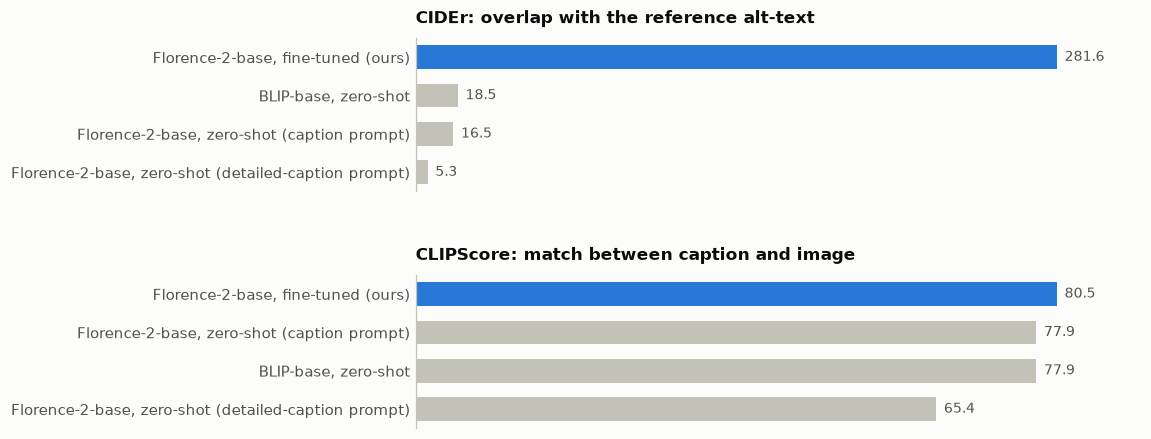

In [5]:
systems = results[results["CIDEr"].notna()]

fig, axes = plt.subplots(2, 1, figsize=(8.5, 4.6), gridspec_kw={"hspace": 0.55})
for ax, metric, title in ((axes[0], "CIDEr", "CIDEr: overlap with the reference alt-text"),
                          (axes[1], "CLIPScore", "CLIPScore: match between caption and image")):
    ordered = systems.sort_values(metric, ascending=False)
    ranked_bars(ax, ordered.index, ordered[metric], value_format="{:.1f}",
                color=[BLUE if name == OURS_LABEL else AXIS for name in ordered.index])
    ax.set_title(title)
plt.show()

The CLIPScore gap is small in absolute terms, so the next cell checks whether it is more than
noise. Every system captioned the same images, so the comparison is paired: for each image, the
fine-tuned model's score minus the baseline's, with a bootstrap interval on the mean difference.

In [6]:
rng = np.random.default_rng(0)
ours_clip = predictions[f"{OURS}_clipscore"].to_numpy()
rows = []
for name, label in (("florence_zero_shot", "Florence-2 zero-shot"), ("blip_zero_shot", "BLIP zero-shot")):
    diff = ours_clip - predictions[f"{name}_clipscore"].to_numpy()
    boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
    rows.append({"fine-tuned minus": label, "mean difference": diff.mean(),
                 "95% interval, low": np.percentile(boot, 2.5),
                 "95% interval, high": np.percentile(boot, 97.5),
                 "images where fine-tuned is higher": f"{(diff > 0).mean():.0%}"})
display(pd.DataFrame(rows).set_index("fine-tuned minus").style.format("{:.2f}", subset=["mean difference", "95% interval, low", "95% interval, high"]))

,mean difference,"95% interval, low","95% interval, high",images where fine-tuned is higher
fine-tuned minus,,,,
Florence-2 zero-shot,2.59,2.00,3.13,68%
BLIP zero-shot,2.59,1.95,3.21,64%


## 4. What the captions look like

The first figure shows test images chosen at random, not picked for quality.

In [7]:
fields = [(OURS, "FINE-TUNED (OURS)"), ("florence_zero_shot", "FLORENCE-2 ZERO-SHOT"),
          ("florence_zero_shot_detailed", "FLORENCE-2 ZERO-SHOT, DETAILED"),
          ("blip_zero_shot", "BLIP ZERO-SHOT"), ("reference", "REFERENCE ALT-TEXT"),
          ("raw_caption", "ORIGINAL H&M CAPTION")]
fields = [(key, label) for key, label in fields if key in predictions]

sample = predictions.sample(6, random_state=21)
caption_comparison(sample.to_dict("records"), fields, title="Six random test images")
plt.show()

[Output removed from the public repository because it shows H&M product photos. Run this cell to see it.]


### Where the fine-tuned model does worst

The six test images where the fine-tuned model's caption matches the image least, by CLIPScore.

In [8]:
worst = predictions.nsmallest(6, f"{OURS}_clipscore")
caption_comparison(worst.to_dict("records"),
                   [(OURS, "FINE-TUNED (OURS)"), ("reference", "REFERENCE ALT-TEXT")],
                   title="Lowest CLIPScore for the fine-tuned model")
plt.show()

[Output removed from the public repository because it shows H&M product photos. Run this cell to see it.]


What these failures have in common:

- **Close-up photos.** Some catalogue images show only a detail of the garment. The model was
  trained to describe a whole garment, so it still states a length or a sleeve type that the
  crop does not show.
- **Multi-colour and printed garments.** The colour and pattern in the references come from
  catalogue labels, which are sometimes wrong for such items, and the model inherits that. It
  also never spells out printed text, which is the intended behaviour for brand names.
- **Small details asserted without evidence.** Pockets, fly type or a "detachable" belt are
  common in the training captions, so the model sometimes adds them when the photo does not
  settle the question.

CLIPScore finds the first two kinds well. It is much less sensitive to the third, so a high
CLIPScore does not mean every detail in a caption is right.

### Does it still claim things it cannot see?

The fine-tuned model was trained on targets with fibre content, linings and similar facts removed.
This checks whether any leak back into its output, and how long its captions are.

Fine-tuned captions containing a non-visible term: 0.0% (0 of 970)


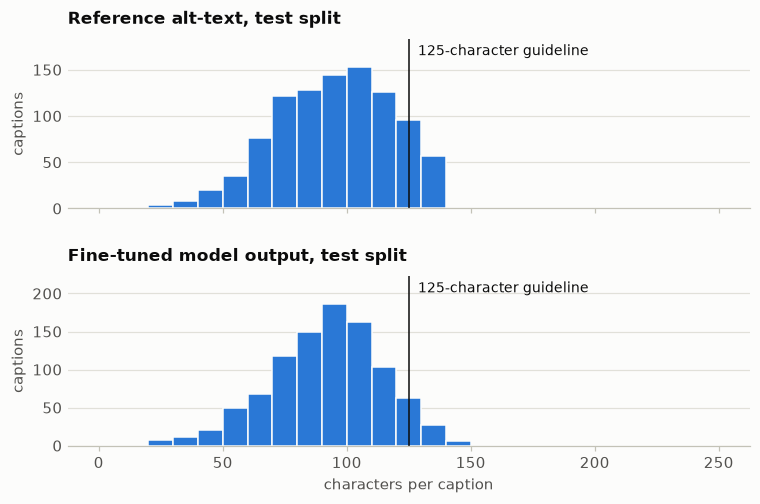

In [9]:
ours = predictions[OURS]
leaks = ours.map(non_visible_terms)
print(f"Fine-tuned captions containing a non-visible term: {leaks.map(bool).mean():.1%} "
      f"({leaks.map(bool).sum()} of {len(ours)})")
if leaks.map(bool).any():
    print("Terms:", pd.Series([t for terms in leaks for t in terms]).value_counts().to_dict())

fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, gridspec_kw={"hspace": 0.4})
bins = range(0, 260, 10)
histogram(axes[0], predictions["reference"].str.len().clip(upper=250), bins=bins)
axes[0].set_title("Reference alt-text, test split")
histogram(axes[1], ours.str.len().clip(upper=250), bins=bins)
axes[1].set_title("Fine-tuned model output, test split")
axes[1].set_xlabel("characters per caption")
for ax in axes:
    reference_line(ax, ALT_TEXT_TARGET_CHARS, f"{ALT_TEXT_TARGET_CHARS}-character guideline")
    ax.set_ylabel("captions")
plt.show()

## 5. Using the model

`scripts/caption.py` does this from the command line. The same thing in Python:

In [10]:
import warnings

warnings.filterwarnings("ignore")  # hide a progress-bar notice that is irrelevant here

from transformers.utils import logging as transformers_logging

from utils.models import load_image, load_system

transformers_logging.disable_progress_bar()

model = load_system(OURS)          # runs on the GPU if there is one, otherwise on the CPU
examples = predictions.sample(3, random_state=5)
for row in examples.itertuples():
    print(row.image, "->", model.caption([load_image(DATA_DIR / row.image)])[0])

images/03919.jpg -> Off white short jacket with a collar, press-studs down the front, long raglan sleeves and side pockets.


images/13447.jpg -> Beige calf-length shirt dress with a collar, wrapover front, buttons down the front, long buttoned sleeves and an asymmetric hem.


images/18526.jpg -> Light orange jacket with a high collar, zip front, zipped chest pocket and long raglan sleeves.
